
# Dataset and Preprocessing Notebook for ST-HRPNet v1

**Paper title:**  
**ST-HRPNet v1: Spatiotemporal Learning for Himawari-Derived Heavy Rainfall Potential Segmentation over Indonesia**

This notebook is prepared specifically for the **Dataset** subsection of the methodology.  
It reproduces the dataset construction and preprocessing pipeline used in the final experiment without changing the experimental meaning.

The notebook covers:

1. Himawari r2w dataset acquisition or local dataset detection.
2. Product validation for B13, B08, B07, B03, HRP, and SND.
3. Indonesia-region cropping from the Southeast Asia large-area domain.
4. Multispectral input-channel normalization.
5. HRP pseudo-label extraction from magenta-colored heavy rainfall potential areas.
6. Temporal sequence construction.
7. Chronological train/validation/test split.
8. Patch-balanced sample preparation for dataset-level illustration.
9. Export of dataset tables and figures for the manuscript.

This notebook does **not** train the model. It is focused only on dataset and preprocessing documentation for the methodology section.


In [1]:

# ============================================================
# 0. INSTALL LIBRARIES
# ============================================================
# Run this cell only if the required libraries are not installed.
# In Google Colab or a fresh Jupyter environment, uncomment the following line.

# !pip install -q opencv-python-headless requests beautifulsoup4 matplotlib pandas tqdm pillow

print("Installation cell is ready. Continue if all libraries are available.")


Installation cell is ready. Continue if all libraries are available.


In [2]:

# ============================================================
# 1. IMPORTS AND ENVIRONMENT SETUP
# ============================================================

import os
import re
import json
import time
import random
import warnings
from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import urljoin

import cv2
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from tqdm.auto import tqdm
from IPython.display import display

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Python environment is ready.")


Python environment is ready.


In [3]:

# ============================================================
# 2. DATASET CONFIGURATION
# ============================================================

PROJECT_NAME = "ST_HRPNet_v1_Dataset_Preprocessing"
PAPER_TITLE = "ST-HRPNet v1: Spatiotemporal Learning for Himawari-Derived Heavy Rainfall Potential Segmentation over Indonesia"

# Official JMA Himawari r2w page.
# Use the official URL, not the translated Google URL, to make parsing stable.
JMA_LIST_URL = "https://www.data.jma.go.jp/mscweb/data/himawari/list_r2w.html"
JMA_ROOT_URL = "https://www.data.jma.go.jp/mscweb/data/himawari/"

# Products used in the final experiment.
INPUT_PRODUCTS = ["b13", "b08", "b07", "b03"]
TARGET_PRODUCT = "hrp"
OPTIONAL_PRODUCTS = ["snd"]

DOWNLOAD_PRODUCTS = []
for p in INPUT_PRODUCTS + [TARGET_PRODUCT] + OPTIONAL_PRODUCTS:
    if p not in DOWNLOAD_PRODUCTS:
        DOWNLOAD_PRODUCTS.append(p)

# JMA r2w Southeast Asia large-area domain.
DOMAIN_BBOX = {
    "lon_min": 90.0,
    "lon_max": 165.0,
    "lat_max": 30.0,
    "lat_min": -15.0,
}

# Indonesia crop used in the experiment.
INDONESIA_BBOX = {
    "lon_min": 95.0,
    "lon_max": 141.0,
    "lat_max": 6.0,
    "lat_min": -11.0,
}

# Final experiment settings preserved for dataset and preprocessing documentation.
SEQ_LEN = 4
IMG_SIZE = (256, 256)
PATCH_SIZE = 128

# If None, all complete timestamps available on the JMA page will be used.
# For quick testing, set MAX_TIMES = 20.
MAX_TIMES = None

# The notebook first tries to use an existing local dataset folder.
# If no local dataset is found and ALLOW_DOWNLOAD is True, it will download the data from JMA.
ALLOW_DOWNLOAD = True
OVERWRITE_DOWNLOAD = False

DATA_ROOT = Path("dataset_himawari_r2w")
LOCAL_RAW_ROOT = DATA_ROOT / "raw"

DATASET_TAG = datetime.now(timezone.utc).strftime("dataset_preprocessing_%Y%m%d_%H%MUTC")
RAW_DIR = LOCAL_RAW_ROOT / DATASET_TAG
OUTPUT_DIR = Path("outputs") / PROJECT_NAME / DATASET_TAG
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"

RAW_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Paper title:", PAPER_TITLE)
print("Input products:", INPUT_PRODUCTS)
print("Target product:", TARGET_PRODUCT)
print("Download/local products:", DOWNLOAD_PRODUCTS)
print("Output directory:", OUTPUT_DIR)


Paper title: ST-HRPNet v1: Spatiotemporal Learning for Himawari-Derived Heavy Rainfall Potential Segmentation over Indonesia
Input products: ['b13', 'b08', 'b07', 'b03']
Target product: hrp
Download/local products: ['b13', 'b08', 'b07', 'b03', 'hrp', 'snd']
Output directory: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC



## Dataset source strategy

This notebook uses the following priority order:

1. **Existing local dataset folder** from a previous ST-HRPNet experiment, if available.
2. **Fresh download from the official JMA Himawari r2w page**, if local files are not found and internet access is available.
3. **Manual extraction option**, if the dataset is stored as a compressed archive such as `dataset_himawari_r2w.rar`.

If a `.rar` archive is available, extract it manually or using WinRAR/7-Zip before running the preprocessing cells. The expected folder structure is:

`dataset_himawari_r2w/raw/<dataset_tag>/<product>/r2w_<product>_<HHMM>.jpg`


In [4]:

# ============================================================
# 3. UTILITY FUNCTIONS FOR DOWNLOAD, LOCAL DETECTION, AND VALIDATION
# ============================================================

def safe_get(url, timeout=60, retries=3, sleep_sec=2):
    """HTTP GET with retry."""
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(url, timeout=timeout)
            r.raise_for_status()
            return r
        except Exception as e:
            last_err = e
            print(f"[Retry {attempt}/{retries}] failed to access {url}: {e}")
            time.sleep(sleep_sec)
    raise RuntimeError(f"Failed to access after {retries} attempts: {url}") from last_err


def is_valid_jpeg(path):
    """Check whether the file exists and can be read as an image."""
    path = Path(path)
    if (not path.exists()) or path.stat().st_size < 1024:
        return False
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    return img is not None and img.size > 0


def parse_jma_r2w_list(list_url=JMA_LIST_URL, root_url=JMA_ROOT_URL):
    """Parse all r2w image links from the official JMA Himawari page."""
    html = safe_get(list_url, timeout=60, retries=3).text
    soup = BeautifulSoup(html, "html.parser")
    rows = []

    pattern = re.compile(r"img/r2w/r2w_([a-z0-9]+)_(\d{4})\.jpg$", re.IGNORECASE)

    for a in soup.find_all("a", href=True):
        href = a["href"]
        m = pattern.search(href)
        if not m:
            continue
        product = m.group(1).lower()
        time_code = m.group(2)
        rows.append({
            "time_code": time_code,
            "product": product,
            "url": urljoin(root_url, href),
            "filename": f"r2w_{product}_{time_code}.jpg",
        })

    df = pd.DataFrame(rows).drop_duplicates()
    if df.empty:
        raise RuntimeError("No r2w image links were parsed from the JMA page.")

    return df.sort_values(["time_code", "product"]).reset_index(drop=True)


def build_complete_table_from_links(df_links, products):
    """Build timestamp table containing all required products from JMA link metadata."""
    pivot = df_links.pivot_table(index="time_code", columns="product", values="url", aggfunc="first")

    missing = [p for p in products if p not in pivot.columns]
    if missing:
        raise ValueError(f"Products not found on JMA page: {missing}. Available products: {sorted(df_links['product'].unique())}")

    complete = pivot.dropna(subset=products).reset_index()
    complete = complete[["time_code"] + products].sort_values("time_code").reset_index(drop=True)

    if MAX_TIMES is not None:
        complete = complete.head(int(MAX_TIMES)).copy()

    if complete.empty:
        raise RuntimeError("No complete timestamps were found for the selected products.")

    return complete


def download_one(url, out_path, overwrite=False):
    """Download one image file and validate it."""
    out_path = Path(out_path)

    if out_path.exists() and (not overwrite) and is_valid_jpeg(out_path):
        return "exists"

    out_path.parent.mkdir(parents=True, exist_ok=True)
    r = safe_get(url, timeout=60, retries=3)
    out_path.write_bytes(r.content)

    if not is_valid_jpeg(out_path):
        raise RuntimeError(f"Downloaded file is not a valid JPEG: {out_path}")

    return "downloaded"


def download_required_dataset(complete_df, products, raw_dir=RAW_DIR, overwrite=False):
    """Download all required Himawari files and return a local manifest."""
    counters = {"downloaded": 0, "exists": 0, "failed": 0}
    errors = []

    pbar = tqdm(total=len(complete_df) * len(products), desc="Downloading Himawari files")
    for _, row in complete_df.iterrows():
        time_code = row["time_code"]
        for product in products:
            url = row[product]
            out_path = raw_dir / product / f"r2w_{product}_{time_code}.jpg"
            try:
                status = download_one(url, out_path, overwrite=overwrite)
                counters[status] += 1
            except Exception as e:
                counters["failed"] += 1
                errors.append({
                    "time_code": time_code,
                    "product": product,
                    "url": url,
                    "out_path": str(out_path),
                    "error": str(e),
                })
            pbar.update(1)
    pbar.close()

    rows = []
    for _, row in complete_df.iterrows():
        time_code = row["time_code"]
        local = {"time_code": time_code}
        ok = True
        for product in products:
            out_path = raw_dir / product / f"r2w_{product}_{time_code}.jpg"
            local[product] = str(out_path)
            local[f"{product}_url"] = row[product]
            if not is_valid_jpeg(out_path):
                ok = False
        local["is_complete_and_valid"] = ok
        rows.append(local)

    manifest = pd.DataFrame(rows)
    error_df = pd.DataFrame(errors)
    return manifest, counters, error_df


def find_existing_raw_dirs(root=LOCAL_RAW_ROOT, products=DOWNLOAD_PRODUCTS):
    """Find existing raw dataset directories that contain required product folders."""
    root = Path(root)
    if not root.exists():
        return []

    candidates = []
    for d in root.glob("*"):
        if not d.is_dir():
            continue
        ok = all((d / p).exists() for p in products)
        if ok:
            n_files = sum(len(list((d / p).glob(f"r2w_{p}_*.jpg"))) for p in products)
            candidates.append((d, n_files))

    candidates = sorted(candidates, key=lambda x: x[1], reverse=True)
    return candidates


def build_manifest_from_local_raw(raw_dir, products=DOWNLOAD_PRODUCTS):
    """Build manifest from an existing local raw Himawari folder."""
    raw_dir = Path(raw_dir)

    product_maps = {}
    time_sets = []
    for product in products:
        files = sorted((raw_dir / product).glob(f"r2w_{product}_*.jpg"))
        mapping = {}
        for f in files:
            m = re.search(rf"r2w_{product}_(\d{{4}})\.jpg$", f.name, re.IGNORECASE)
            if m and is_valid_jpeg(f):
                mapping[m.group(1)] = str(f)
        product_maps[product] = mapping
        time_sets.append(set(mapping.keys()))

    common_times = sorted(set.intersection(*time_sets)) if time_sets else []
    if MAX_TIMES is not None:
        common_times = common_times[:int(MAX_TIMES)]

    rows = []
    for t in common_times:
        row = {"time_code": t}
        ok = True
        for product in products:
            path = product_maps[product].get(t)
            row[product] = path
            row[f"{product}_url"] = None
            if path is None or not is_valid_jpeg(path):
                ok = False
        row["is_complete_and_valid"] = ok
        rows.append(row)

    return pd.DataFrame(rows)


print("Utility functions are ready.")


Utility functions are ready.


In [5]:

# ============================================================
# 4. ACQUIRE OR LOAD DATASET MANIFEST
# ============================================================

existing_dirs = find_existing_raw_dirs()
print("Existing raw dataset candidates:")
for d, n in existing_dirs[:5]:
    print(f"- {d} ({n} files)")

if existing_dirs:
    # Use the largest existing dataset folder.
    RAW_SOURCE_DIR = existing_dirs[0][0]
    print("\nUsing existing local dataset:", RAW_SOURCE_DIR)
    manifest = build_manifest_from_local_raw(RAW_SOURCE_DIR, DOWNLOAD_PRODUCTS)
    counters = {"downloaded": 0, "exists": int(manifest["is_complete_and_valid"].sum() * len(DOWNLOAD_PRODUCTS)), "failed": 0}
    error_df = pd.DataFrame()
else:
    if not ALLOW_DOWNLOAD:
        raise RuntimeError(
            "No local dataset was found and ALLOW_DOWNLOAD=False. "
            "Extract the dataset archive or set ALLOW_DOWNLOAD=True."
        )

    print("\nNo local dataset found. Downloading from JMA...")
    df_links = parse_jma_r2w_list()
    print("Products available on JMA page:", sorted(df_links["product"].unique()))
    complete_table = build_complete_table_from_links(df_links, DOWNLOAD_PRODUCTS)
    print("Complete timestamps:", len(complete_table))

    manifest, counters, error_df = download_required_dataset(
        complete_table,
        DOWNLOAD_PRODUCTS,
        raw_dir=RAW_DIR,
        overwrite=OVERWRITE_DOWNLOAD
    )
    RAW_SOURCE_DIR = RAW_DIR

manifest = manifest[manifest["is_complete_and_valid"]].sort_values("time_code").reset_index(drop=True)

manifest_path = TABLE_DIR / "dataset_manifest.csv"
manifest.to_csv(manifest_path, index=False)

if not error_df.empty:
    error_path = TABLE_DIR / "download_errors.csv"
    error_df.to_csv(error_path, index=False)
    print("Download errors saved:", error_path)

print("\nDataset counters:", counters)
print("Valid timestamps:", len(manifest))
print("Manifest saved:", manifest_path)

display(manifest.head())

if len(manifest) < SEQ_LEN:
    raise RuntimeError(f"Valid timestamps ({len(manifest)}) are fewer than SEQ_LEN ({SEQ_LEN}).")


Existing raw dataset candidates:
- dataset_himawari_r2w\raw\jma_snapshot_20260529_0126UTC (852 files)

Using existing local dataset: dataset_himawari_r2w\raw\jma_snapshot_20260529_0126UTC

Dataset counters: {'downloaded': 0, 'exists': 852, 'failed': 0}
Valid timestamps: 142
Manifest saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\tables\dataset_manifest.csv


,time_code,b13,b13_url,b08,b08_url,b07,b07_url,b03,b03_url,hrp,hrp_url,snd,snd_url,is_complete_and_valid
0,0000,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,True
1,0010,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,True
2,0020,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,True
3,0030,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,True
4,0040,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,dataset_himawari_r2w\raw\jma_snapshot_20260529...,None,True


In [6]:

# ============================================================
# 5. IMAGE READING, GEOGRAPHIC CROP, AND RESIZING
# ============================================================

def read_rgb(path):
    """Read image as RGB."""
    img_bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img_bgr is None:
        raise FileNotFoundError(f"Cannot read image: {path}")
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)


def lonlat_to_pixel(lon, lat, width, height, domain=DOMAIN_BBOX):
    """Convert lon/lat to pixel coordinates for the rectangular r2w display domain."""
    x = (lon - domain["lon_min"]) / (domain["lon_max"] - domain["lon_min"]) * width
    y = (domain["lat_max"] - lat) / (domain["lat_max"] - domain["lat_min"]) * height
    return int(round(x)), int(round(y))


def crop_bbox(img_rgb, bbox=INDONESIA_BBOX, domain=DOMAIN_BBOX):
    """Crop image using approximate geographic bounding box."""
    h, w = img_rgb.shape[:2]

    x1, y1 = lonlat_to_pixel(bbox["lon_min"], bbox["lat_max"], w, h, domain)
    x2, y2 = lonlat_to_pixel(bbox["lon_max"], bbox["lat_min"], w, h, domain)

    x1, x2 = sorted([max(0, x1), min(w, x2)])
    y1, y2 = sorted([max(0, y1), min(h, y2)])

    if x2 <= x1 or y2 <= y1:
        raise ValueError("Invalid crop bounding box. Check DOMAIN_BBOX and INDONESIA_BBOX.")

    return img_rgb[y1:y2, x1:x2]


def resize_rgb(img_rgb, size=IMG_SIZE, interpolation=cv2.INTER_AREA):
    """Resize RGB image to model input size."""
    return cv2.resize(img_rgb, size, interpolation=interpolation)


# Preview original and cropped size using the first valid sample.
sample_idx = min(10, len(manifest) - 1)
sample = manifest.iloc[sample_idx]
sample_rgb = read_rgb(sample["b13"])
sample_crop = crop_bbox(sample_rgb)
sample_resized = resize_rgb(sample_crop)

print("Sample time_code:", sample["time_code"])
print("Original shape:", sample_rgb.shape)
print("Indonesia crop shape:", sample_crop.shape)
print("Resized shape:", sample_resized.shape)


Sample time_code: 0140
Original shape: (901, 1501, 3)
Indonesia crop shape: (340, 921, 3)
Resized shape: (256, 256, 3)


In [7]:

# ============================================================
# 6. INPUT CHANNEL NORMALIZATION AND HRP MASK EXTRACTION
# ============================================================

def product_to_input_channel(path, product):
    """Convert each display-product image to one normalized input channel."""
    rgb = read_rgb(path)
    cropped = crop_bbox(rgb)
    resized = resize_rgb(cropped, IMG_SIZE)

    gray = cv2.cvtColor(resized, cv2.COLOR_RGB2GRAY).astype("float32") / 255.0

    p2, p98 = np.percentile(gray, [2, 98])
    if p98 > p2:
        gray = np.clip((gray - p2) / (p98 - p2), 0.0, 1.0)

    return gray[..., None]


def extract_hrp_magenta_mask_from_rgb(rgb):
    """Extract binary HRP pseudo-label from magenta-colored HRP regions."""
    r = rgb[..., 0].astype(np.int16)
    g = rgb[..., 1].astype(np.int16)
    b = rgb[..., 2].astype(np.int16)

    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    h = hsv[..., 0]
    s = hsv[..., 1]
    v = hsv[..., 2]

    magenta_rgb = (r >= 145) & (b >= 110) & (g <= 140) & ((r - g) >= 45) & ((b - g) >= 20)
    magenta_hsv = (s >= 50) & (v >= 80) & ((h >= 125) | (h <= 5))

    mask = (magenta_rgb & magenta_hsv).astype(np.uint8)

    # Light morphological cleaning. This is intentionally not aggressive.
    kernel_open = np.ones((2, 2), np.uint8)
    kernel_close = np.ones((3, 3), np.uint8)

    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open, iterations=1)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close, iterations=1)

    return mask.astype("float32")


def target_to_mask(path, product=TARGET_PRODUCT):
    """Convert HRP display product to binary mask."""
    if product.lower() != "hrp":
        raise ValueError("This dataset notebook is designed for TARGET_PRODUCT='hrp'.")

    rgb = read_rgb(path)
    cropped = crop_bbox(rgb)
    resized = resize_rgb(cropped, IMG_SIZE)

    mask = extract_hrp_magenta_mask_from_rgb(resized)
    return mask[..., None]


def build_multispectral_frame(row, input_products=INPUT_PRODUCTS):
    """Build one multispectral frame from selected Himawari products."""
    channels = [product_to_input_channel(row[p], p) for p in input_products]
    return np.concatenate(channels, axis=-1)


# Test preprocessing on one sample.
x_sample = build_multispectral_frame(sample)
y_sample = target_to_mask(sample[TARGET_PRODUCT])

print("Multispectral frame shape:", x_sample.shape)
print("HRP mask shape:", y_sample.shape)
print("HRP positive-pixel ratio:", float(y_sample.mean()))


Multispectral frame shape: (256, 256, 4)
HRP mask shape: (256, 256, 1)
HRP positive-pixel ratio: 0.00616455078125


Sample time code: 0140

PRODUCT: B13
Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\actual_original_b13_0140.png


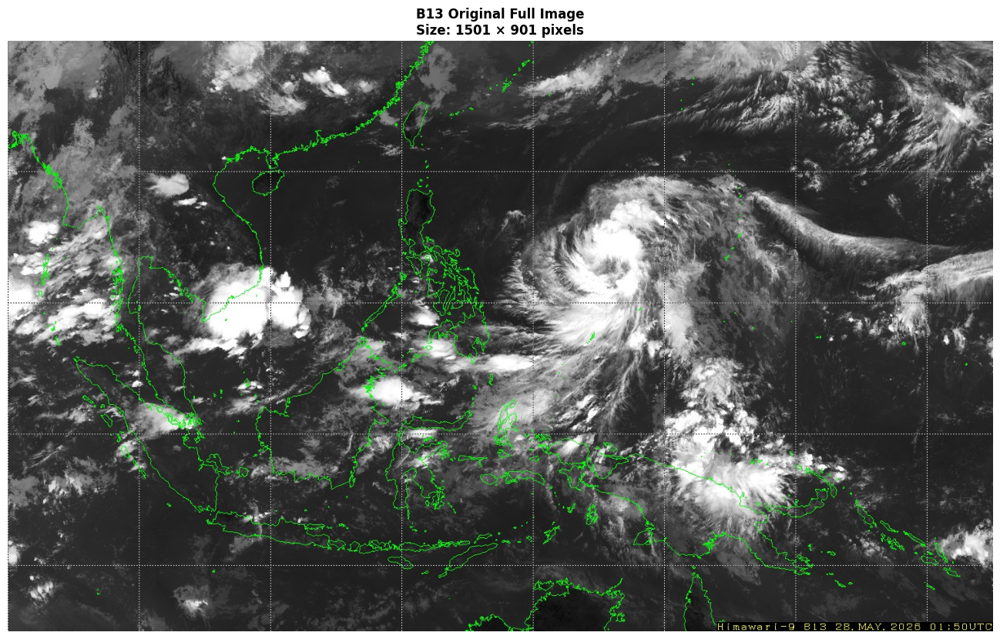

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\actual_crop_b13_0140.png


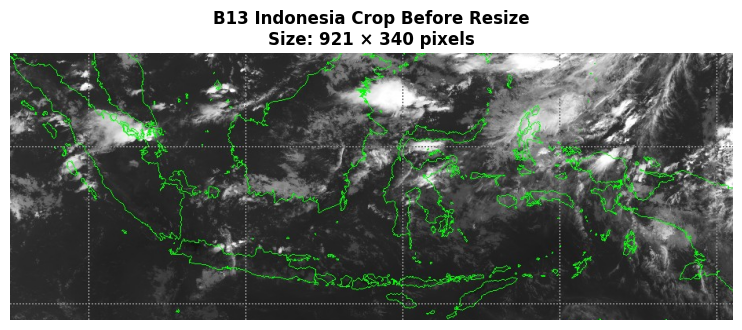

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\model_ready_b13_0140.png


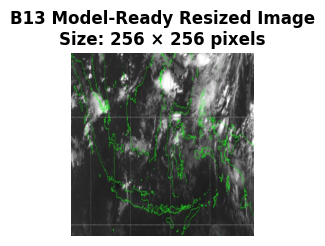


PRODUCT: B08
Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\actual_original_b08_0140.png


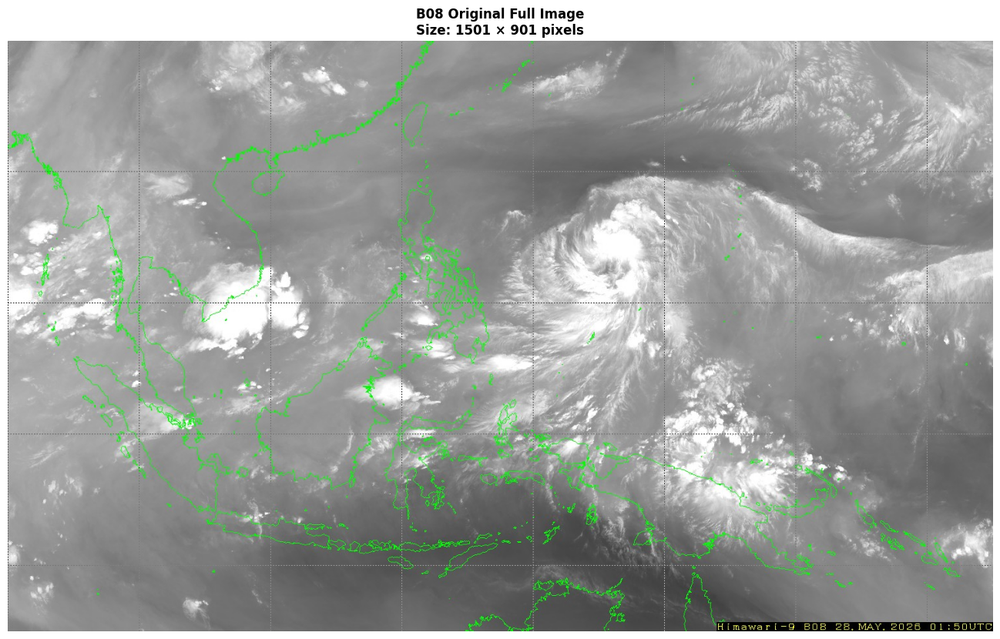

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\actual_crop_b08_0140.png


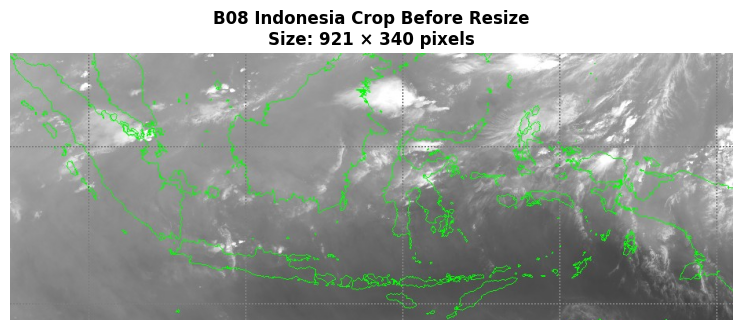

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\model_ready_b08_0140.png


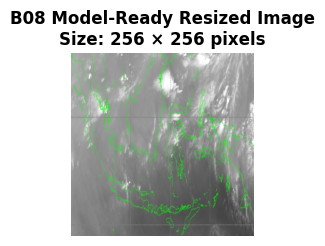


PRODUCT: B07
Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\actual_original_b07_0140.png


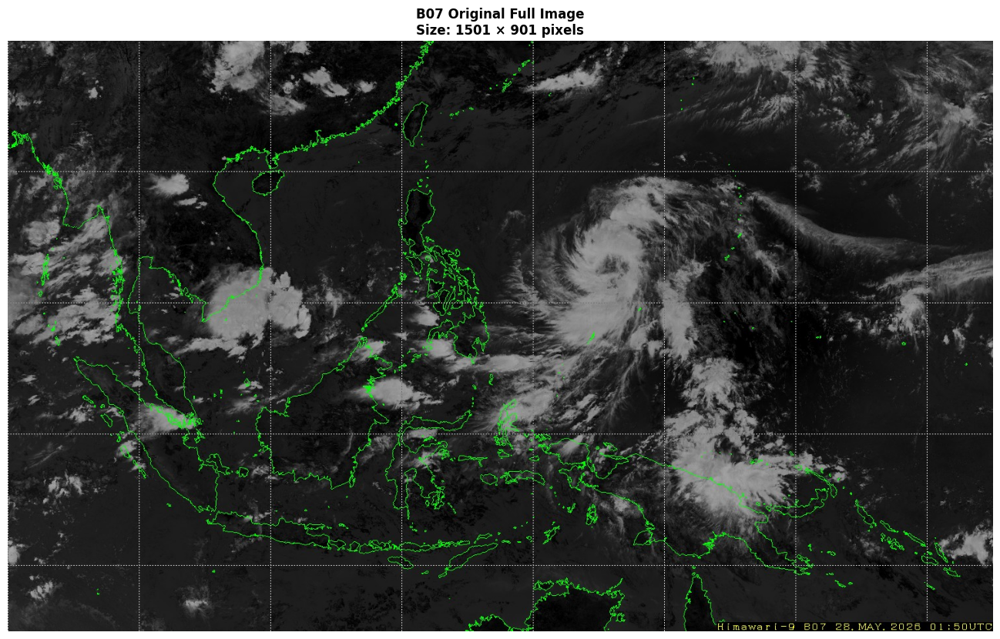

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\actual_crop_b07_0140.png


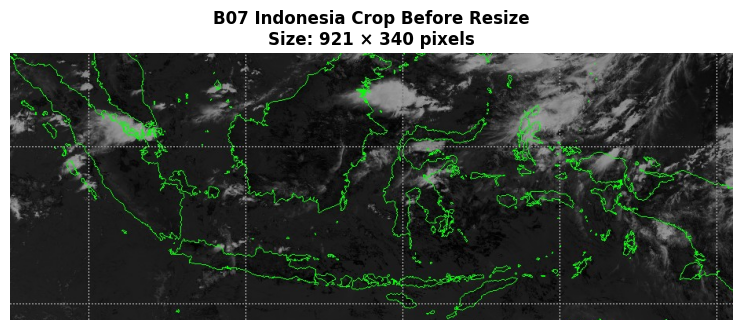

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\model_ready_b07_0140.png


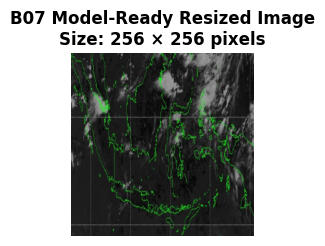


PRODUCT: B03
Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\actual_original_b03_0140.png


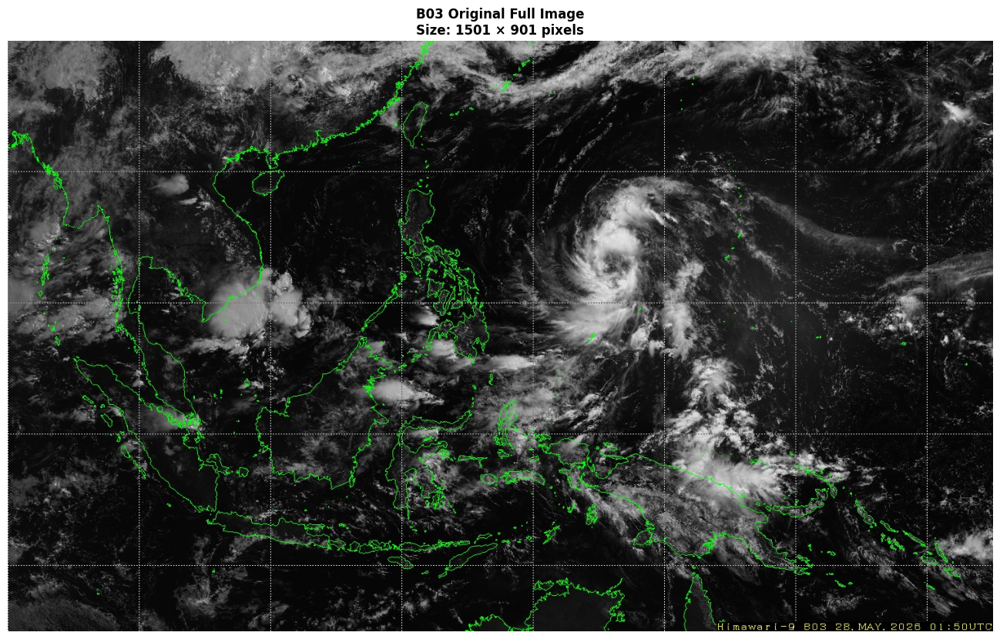

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\actual_crop_b03_0140.png


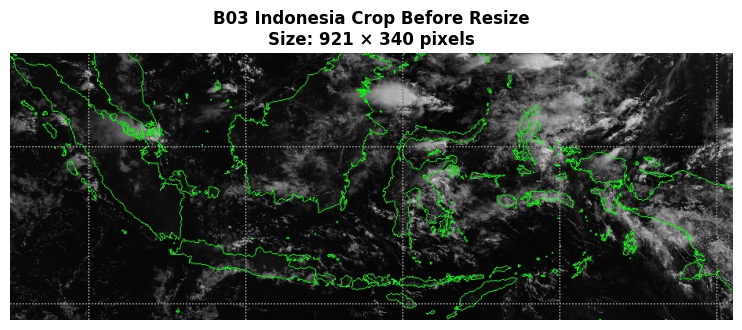

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\model_ready_b03_0140.png


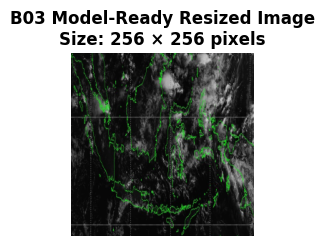


PRODUCT: HRP
Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\actual_original_hrp_0140.png


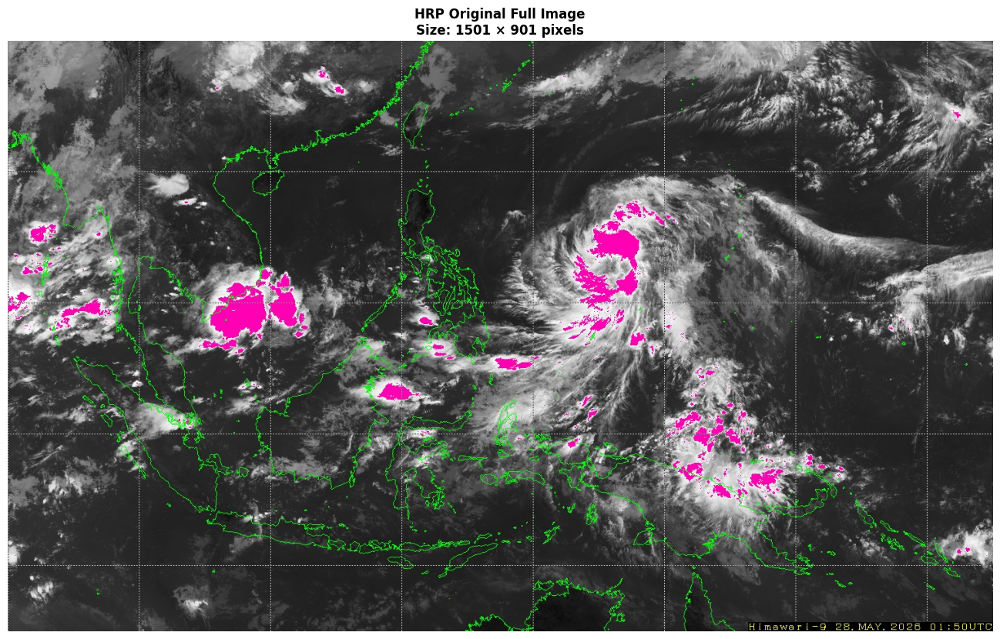

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\actual_crop_hrp_0140.png


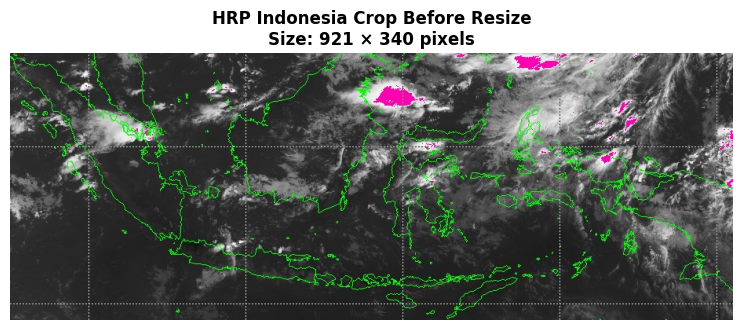

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\model_ready_hrp_0140.png


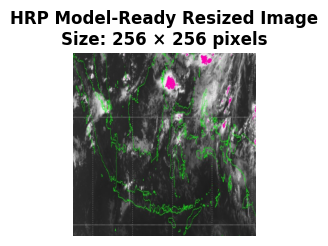


PRODUCT: SND
Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\actual_original_snd_0140.png


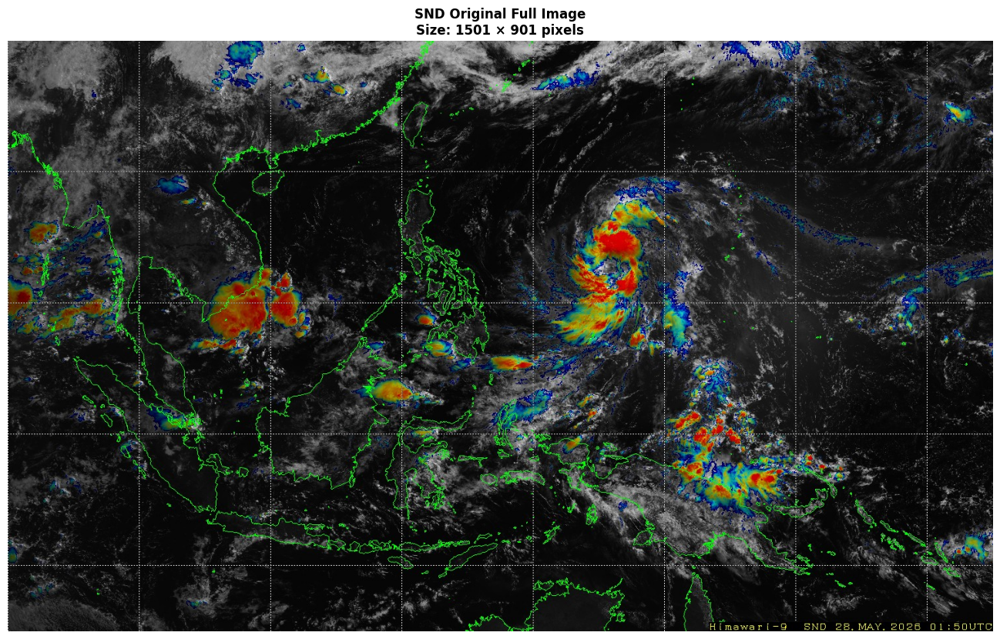

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\actual_crop_snd_0140.png


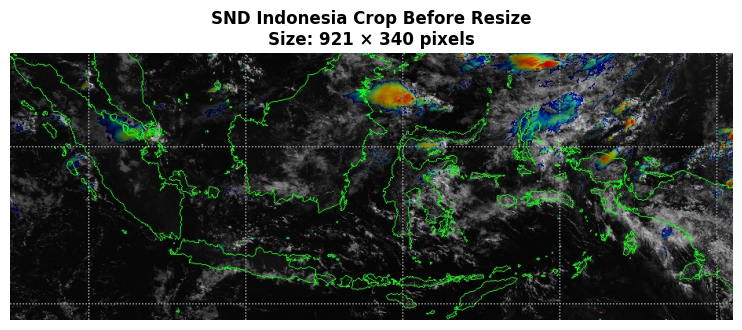

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\model_ready_snd_0140.png


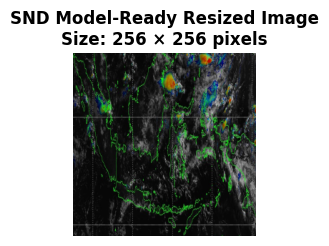

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\normalized_b13_model_input_0140.png


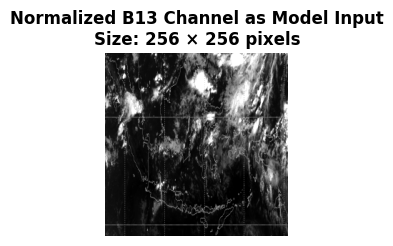

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\extracted_hrp_mask_0140.png


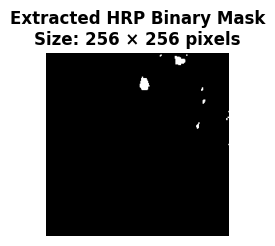

In [17]:
# ============================================================
# 7. VISUALIZE REPRESENTATIVE SAMPLE DATA AND PREPROCESSING RESULT
#    ACTUAL SIZE DISPLAY VERSION
# ============================================================

def show_image_actual_size(img, title="", cmap=None, max_display_width=14, dpi=100, save_path=None):
    """
    Display image close to its actual pixel aspect ratio.

    max_display_width controls how large the image appears in notebook.
    It does not change the image data.
    """
    h, w = img.shape[:2]

    # Convert pixel dimension to figure size while limiting very large display.
    fig_w = min(max_display_width, w / dpi)
    fig_h = fig_w * (h / w)

    fig = plt.figure(figsize=(fig_w, fig_h), dpi=dpi)

    if cmap is None:
        plt.imshow(img)
    else:
        plt.imshow(img, cmap=cmap)

    plt.title(f"{title}\nSize: {w} × {h} pixels", fontsize=12, fontweight="bold")
    plt.axis("off")
    plt.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight")
        print("Saved:", save_path)

    plt.show()


def show_dataset_sample_actual_size(row, save_dir=FIG_DIR):
    """
    Display each Himawari product one by one:
    1. Original full image
    2. Indonesia crop before resizing
    3. Model-ready resized image
    """
    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)

    print("Sample time code:", row["time_code"])
    print("=" * 80)

    for product in DOWNLOAD_PRODUCTS:
        print(f"\nPRODUCT: {product.upper()}")

        # ----------------------------------------------------
        # A. Original full image from JMA file
        # ----------------------------------------------------
        original_rgb = read_rgb(row[product])
        show_image_actual_size(
            original_rgb,
            title=f"{product.upper()} Original Full Image",
            max_display_width=14,
            dpi=100,
            save_path=save_dir / f"actual_original_{product}_{row['time_code']}.png"
        )

        # ----------------------------------------------------
        # B. Indonesia crop before resizing
        # ----------------------------------------------------
        cropped_rgb = crop_bbox(original_rgb)
        show_image_actual_size(
            cropped_rgb,
            title=f"{product.upper()} Indonesia Crop Before Resize",
            max_display_width=14,
            dpi=100,
            save_path=save_dir / f"actual_crop_{product}_{row['time_code']}.png"
        )

        # ----------------------------------------------------
        # C. Model-ready resized image
        # ----------------------------------------------------
        resized_rgb = resize_rgb(cropped_rgb, IMG_SIZE)
        show_image_actual_size(
            resized_rgb,
            title=f"{product.upper()} Model-Ready Resized Image",
            max_display_width=7,
            dpi=100,
            save_path=save_dir / f"model_ready_{product}_{row['time_code']}.png"
        )

    # --------------------------------------------------------
    # D. Normalized B13 model input channel
    # --------------------------------------------------------
    x_frame = build_multispectral_frame(row)
    normalized_b13 = x_frame[..., INPUT_PRODUCTS.index("b13")]

    show_image_actual_size(
        normalized_b13,
        title="Normalized B13 Channel as Model Input",
        cmap="gray",
        max_display_width=7,
        dpi=100,
        save_path=save_dir / f"normalized_b13_model_input_{row['time_code']}.png"
    )

    # --------------------------------------------------------
    # E. Extracted HRP binary mask
    # --------------------------------------------------------
    y_mask = target_to_mask(row[TARGET_PRODUCT])

    show_image_actual_size(
        y_mask[..., 0],
        title=f"Extracted {TARGET_PRODUCT.upper()} Binary Mask",
        cmap="gray",
        max_display_width=7,
        dpi=100,
        save_path=save_dir / f"extracted_{TARGET_PRODUCT}_mask_{row['time_code']}.png"
    )


show_dataset_sample_actual_size(sample, FIG_DIR)

In [9]:

# ============================================================
# 8. BUILD FULL TEMPORAL SEQUENCES
# ============================================================

def build_sequences_from_manifest(df, seq_len=SEQ_LEN, input_products=INPUT_PRODUCTS, target_product=TARGET_PRODUCT):
    """Build full temporal sequences.

    X shape: (N, T, H, W, C)
    y shape: (N, H, W, 1)
    """
    df = df[df["is_complete_and_valid"]].sort_values("time_code").reset_index(drop=True)

    if len(df) < seq_len:
        raise RuntimeError("The number of valid timestamps is smaller than SEQ_LEN.")

    X, y, meta_rows = [], [], []

    for end_idx in tqdm(range(seq_len - 1, len(df)), desc="Building temporal sequences"):
        seq_df = df.iloc[end_idx - seq_len + 1:end_idx + 1]
        target_row = df.iloc[end_idx]

        frames = []
        for _, row in seq_df.iterrows():
            frames.append(build_multispectral_frame(row, input_products))

        X.append(np.stack(frames, axis=0))
        y.append(target_to_mask(target_row[target_product], product=target_product))

        meta_rows.append({
            "sequence_index": len(meta_rows),
            "sequence_time_codes": ",".join(seq_df["time_code"].tolist()),
            "target_time_code": target_row["time_code"],
            "target_path": target_row[target_product],
        })

    X = np.asarray(X, dtype="float32")
    y = np.asarray(y, dtype="float32")
    meta = pd.DataFrame(meta_rows)

    return X, y, meta


X, y, meta = build_sequences_from_manifest(manifest)

sequence_meta_path = TABLE_DIR / "sequence_metadata.csv"
meta.to_csv(sequence_meta_path, index=False)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Overall positive-pixel ratio:", float(y.mean()))
print("Sequence metadata saved:", sequence_meta_path)

display(meta.head())


Building temporal sequences:   0%|          | 0/139 [00:00<?, ?it/s]

X shape: (139, 4, 256, 256, 4)
y shape: (139, 256, 256, 1)
Overall positive-pixel ratio: 0.020628895610570908
Sequence metadata saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\tables\sequence_metadata.csv


,sequence_index,sequence_time_codes,target_time_code,target_path
0,0,"0000,0010,0020,0030",0030,dataset_himawari_r2w\raw\jma_snapshot_20260529...
1,1,"0010,0020,0030,0040",0040,dataset_himawari_r2w\raw\jma_snapshot_20260529...
2,2,"0020,0030,0040,0050",0050,dataset_himawari_r2w\raw\jma_snapshot_20260529...
3,3,"0030,0040,0050,0100",0100,dataset_himawari_r2w\raw\jma_snapshot_20260529...
4,4,"0040,0050,0100,0110",0110,dataset_himawari_r2w\raw\jma_snapshot_20260529...


In [10]:

# ============================================================
# 9. CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

def temporal_split(X, y, meta, train_ratio=0.70, val_ratio=0.15):
    """Chronological split to reduce leakage among adjacent satellite timestamps."""
    n = len(X)

    train_end = int(n * train_ratio)
    val_end = int(n * (train_ratio + val_ratio))

    X_train, y_train = X[:train_end], y[:train_end]
    X_val, y_val = X[train_end:val_end], y[train_end:val_end]
    X_test, y_test = X[val_end:], y[val_end:]

    meta_train = meta.iloc[:train_end].reset_index(drop=True)
    meta_val = meta.iloc[train_end:val_end].reset_index(drop=True)
    meta_test = meta.iloc[val_end:].reset_index(drop=True)

    if min(len(X_train), len(X_val), len(X_test)) <= 0:
        raise RuntimeError("Train/validation/test split produced an empty subset.")

    return (X_train, y_train, meta_train), (X_val, y_val, meta_val), (X_test, y_test, meta_test)


(train_data, val_data, test_data) = temporal_split(X, y, meta)
X_train, y_train, meta_train = train_data
X_val, y_val, meta_val = val_data
X_test, y_test, meta_test = test_data

split_summary = pd.DataFrame([
    {"split": "train", "n_sequences": len(X_train), "positive_pixel_ratio": float(y_train.mean())},
    {"split": "validation", "n_sequences": len(X_val), "positive_pixel_ratio": float(y_val.mean())},
    {"split": "test", "n_sequences": len(X_test), "positive_pixel_ratio": float(y_test.mean())},
])

split_summary_path = TABLE_DIR / "dataset_split_summary.csv"
split_summary.to_csv(split_summary_path, index=False)

display(split_summary)
print("Split summary saved:", split_summary_path)


,split,n_sequences,positive_pixel_ratio
0,train,97,0.018517
1,validation,21,0.025724
2,test,21,0.025287


Split summary saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\tables\dataset_split_summary.csv


Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\figure_temporal_sequence_sample_005_b13_paper_ready.png


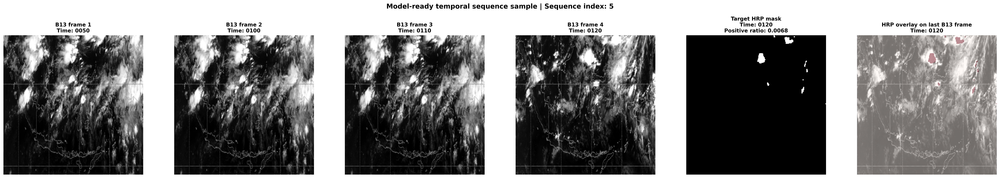

In [18]:
# ============================================================
# 10. VISUALIZE TEMPORAL SEQUENCE SAMPLE
#     PAPER-READY VERSION
# ============================================================

def show_sequence_sample_paper_ready(
    seq_idx=0,
    channel_name="b13",
    save=True,
    dpi=300,
    show_overlay=True
):
    """
    Visualize temporal sequence sample in a paper-ready layout.

    Important:
    - This function visualizes X and y after preprocessing.
    - Therefore, the displayed images are model-ready inputs:
      cropped, resized to IMG_SIZE, normalized, and arranged as temporal sequences.
    - This is appropriate for explaining the model input in the Dataset/Preprocessing section.
    """

    seq_idx = int(min(max(seq_idx, 0), len(X) - 1))

    if channel_name not in INPUT_PRODUCTS:
        raise ValueError(f"channel_name must be one of {INPUT_PRODUCTS}")

    ch_idx = INPUT_PRODUCTS.index(channel_name)

    seq_times = meta.iloc[seq_idx]["sequence_time_codes"].split(",")
    target_time = meta.iloc[seq_idx]["target_time_code"]

    # Number of panels:
    # T temporal frames + target mask + optional overlay
    n_extra = 2 if show_overlay else 1
    n_cols = SEQ_LEN + n_extra

    fig = plt.figure(figsize=(5 * n_cols, 5), dpi=dpi)

    # --------------------------------------------------------
    # A. Show temporal frames
    # --------------------------------------------------------
    for t in range(SEQ_LEN):
        ax = plt.subplot(1, n_cols, t + 1)

        frame = X[seq_idx, t, ..., ch_idx]
        ax.imshow(frame, cmap="gray", vmin=0, vmax=1)

        ax.set_title(
            f"{channel_name.upper()} frame {t+1}\nTime: {seq_times[t]}",
            fontsize=11,
            fontweight="bold"
        )
        ax.axis("off")

    # --------------------------------------------------------
    # B. Show target HRP mask
    # --------------------------------------------------------
    target_mask = y[seq_idx, ..., 0]

    ax = plt.subplot(1, n_cols, SEQ_LEN + 1)
    ax.imshow(target_mask, cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"Target HRP mask\nTime: {target_time}\nPositive ratio: {target_mask.mean():.4f}",
        fontsize=11,
        fontweight="bold"
    )
    ax.axis("off")

    # --------------------------------------------------------
    # C. Show overlay on last temporal frame
    # --------------------------------------------------------
    if show_overlay:
        last_frame = X[seq_idx, -1, ..., ch_idx]

        ax = plt.subplot(1, n_cols, SEQ_LEN + 2)
        ax.imshow(last_frame, cmap="gray", vmin=0, vmax=1)
        ax.imshow(target_mask, cmap="Reds", alpha=0.45, vmin=0, vmax=1)

        ax.set_title(
            f"HRP overlay on last {channel_name.upper()} frame\nTime: {target_time}",
            fontsize=11,
            fontweight="bold"
        )
        ax.axis("off")

    plt.suptitle(
        f"Model-ready temporal sequence sample | Sequence index: {seq_idx}",
        fontsize=14,
        fontweight="bold",
        y=1.03
    )

    plt.tight_layout()

    if save:
        out_path = FIG_DIR / f"figure_temporal_sequence_sample_{seq_idx:03d}_{channel_name}_paper_ready.png"
        fig.savefig(out_path, dpi=dpi, bbox_inches="tight")
        print("Saved:", out_path)

    plt.show()


show_sequence_sample_paper_ready(
    seq_idx=min(5, len(X)-1),
    channel_name="b13",
    save=True,
    dpi=300,
    show_overlay=True
)

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\figure_temporal_sequence_sample_005_b13_vertical.png


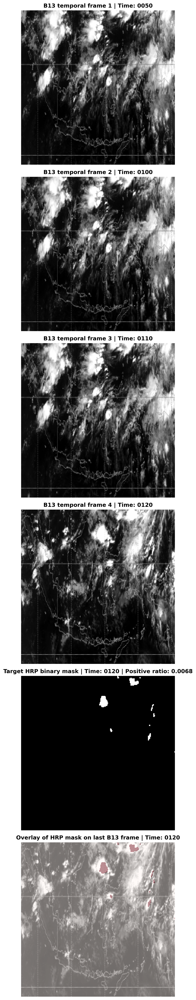

In [19]:
# ============================================================
# 10B. VISUALIZE TEMPORAL SEQUENCE SAMPLE
#      VERTICAL VERSION: ONE FRAME PER ROW
# ============================================================

def show_sequence_sample_vertical(
    seq_idx=0,
    channel_name="b13",
    save=True,
    dpi=300
):
    """
    Display temporal sequence vertically, one image per row.
    This is useful when the horizontal figure looks too small in the notebook.
    """

    seq_idx = int(min(max(seq_idx, 0), len(X) - 1))

    if channel_name not in INPUT_PRODUCTS:
        raise ValueError(f"channel_name must be one of {INPUT_PRODUCTS}")

    ch_idx = INPUT_PRODUCTS.index(channel_name)

    seq_times = meta.iloc[seq_idx]["sequence_time_codes"].split(",")
    target_time = meta.iloc[seq_idx]["target_time_code"]

    n_rows = SEQ_LEN + 2

    fig = plt.figure(figsize=(8, 5 * n_rows), dpi=dpi)

    # --------------------------------------------------------
    # A. Temporal frames
    # --------------------------------------------------------
    for t in range(SEQ_LEN):
        ax = plt.subplot(n_rows, 1, t + 1)

        frame = X[seq_idx, t, ..., ch_idx]
        ax.imshow(frame, cmap="gray", vmin=0, vmax=1)

        ax.set_title(
            f"{channel_name.upper()} temporal frame {t+1} | Time: {seq_times[t]}",
            fontsize=12,
            fontweight="bold"
        )
        ax.axis("off")

    # --------------------------------------------------------
    # B. Target HRP mask
    # --------------------------------------------------------
    target_mask = y[seq_idx, ..., 0]

    ax = plt.subplot(n_rows, 1, SEQ_LEN + 1)
    ax.imshow(target_mask, cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"Target HRP binary mask | Time: {target_time} | Positive ratio: {target_mask.mean():.4f}",
        fontsize=12,
        fontweight="bold"
    )
    ax.axis("off")

    # --------------------------------------------------------
    # C. Overlay
    # --------------------------------------------------------
    last_frame = X[seq_idx, -1, ..., ch_idx]

    ax = plt.subplot(n_rows, 1, SEQ_LEN + 2)
    ax.imshow(last_frame, cmap="gray", vmin=0, vmax=1)
    ax.imshow(target_mask, cmap="Reds", alpha=0.45, vmin=0, vmax=1)
    ax.set_title(
        f"Overlay of HRP mask on last {channel_name.upper()} frame | Time: {target_time}",
        fontsize=12,
        fontweight="bold"
    )
    ax.axis("off")

    plt.tight_layout()

    if save:
        out_path = FIG_DIR / f"figure_temporal_sequence_sample_{seq_idx:03d}_{channel_name}_vertical.png"
        fig.savefig(out_path, dpi=dpi, bbox_inches="tight")
        print("Saved:", out_path)

    plt.show()


show_sequence_sample_vertical(
    seq_idx=min(5, len(X)-1),
    channel_name="b13",
    save=True,
    dpi=300
)

In [12]:

# ============================================================
# 11. PATCH-BALANCED SAMPLING FOR DATASET ILLUSTRATION
# ============================================================

MIN_POSITIVE_PIXELS = 16
NEGATIVE_MAX_POSITIVE_RATIO = 0.0005


def clamp_int(v, low, high):
    return int(max(low, min(high, v)))


def crop_patch_x_y(X_img, y_img, top, left, patch_size=PATCH_SIZE):
    x_patch = X_img[:, top:top+patch_size, left:left+patch_size, :]
    y_patch = y_img[top:top+patch_size, left:left+patch_size, :]
    return x_patch, y_patch


def sample_positive_patch(X_arr, y_arr, patch_size=PATCH_SIZE, min_positive_pixels=MIN_POSITIVE_PIXELS, max_trials=100):
    n, t, h, w, c = X_arr.shape
    pos_img_indices = np.where(y_arr.reshape(n, -1).sum(axis=1) >= min_positive_pixels)[0]

    if len(pos_img_indices) == 0:
        raise RuntimeError("No image contains enough HRP-positive pixels for positive patch sampling.")

    for _ in range(max_trials):
        idx = int(np.random.choice(pos_img_indices))
        ys, xs = np.where(y_arr[idx, ..., 0] > 0.5)

        if len(xs) == 0:
            continue

        k = np.random.randint(0, len(xs))
        cy, cx = int(ys[k]), int(xs[k])

        top = clamp_int(cy - patch_size // 2 + np.random.randint(-patch_size//4, patch_size//4 + 1), 0, h - patch_size)
        left = clamp_int(cx - patch_size // 2 + np.random.randint(-patch_size//4, patch_size//4 + 1), 0, w - patch_size)

        xp, yp = crop_patch_x_y(X_arr[idx], y_arr[idx], top, left, patch_size)

        if yp.sum() >= min_positive_pixels:
            return idx, top, left, xp, yp

    idx = int(np.random.choice(pos_img_indices))
    ys, xs = np.where(y_arr[idx, ..., 0] > 0.5)
    k = np.random.randint(0, len(xs))
    cy, cx = int(ys[k]), int(xs[k])

    top = clamp_int(cy - patch_size // 2, 0, h - patch_size)
    left = clamp_int(cx - patch_size // 2, 0, w - patch_size)

    xp, yp = crop_patch_x_y(X_arr[idx], y_arr[idx], top, left, patch_size)
    return idx, top, left, xp, yp


def sample_negative_patch(X_arr, y_arr, patch_size=PATCH_SIZE, max_positive_ratio=NEGATIVE_MAX_POSITIVE_RATIO, max_trials=200):
    n, t, h, w, c = X_arr.shape

    for _ in range(max_trials):
        idx = np.random.randint(0, n)
        top = np.random.randint(0, h - patch_size + 1)
        left = np.random.randint(0, w - patch_size + 1)

        xp, yp = crop_patch_x_y(X_arr[idx], y_arr[idx], top, left, patch_size)

        if float(yp.mean()) <= max_positive_ratio:
            return idx, top, left, xp, yp

    best = None
    best_ratio = 1.0

    for _ in range(50):
        idx = np.random.randint(0, n)
        top = np.random.randint(0, h - patch_size + 1)
        left = np.random.randint(0, w - patch_size + 1)

        xp, yp = crop_patch_x_y(X_arr[idx], y_arr[idx], top, left, patch_size)
        ratio = float(yp.mean())

        if ratio < best_ratio:
            best_ratio = ratio
            best = (idx, top, left, xp, yp)

    return best


# Draw examples from training split only, as done in the experiment.
pos_idx, pos_top, pos_left, pos_x, pos_y = sample_positive_patch(X_train, y_train)
neg_idx, neg_top, neg_left, neg_x, neg_y = sample_negative_patch(X_train, y_train)

patch_info = pd.DataFrame([
    {
        "patch_type": "positive_patch",
        "source_sequence_index_train": int(pos_idx),
        "top": int(pos_top),
        "left": int(pos_left),
        "positive_pixel_ratio": float(pos_y.mean()),
    },
    {
        "patch_type": "negative_patch",
        "source_sequence_index_train": int(neg_idx),
        "top": int(neg_top),
        "left": int(neg_left),
        "positive_pixel_ratio": float(neg_y.mean()),
    },
])

patch_info_path = TABLE_DIR / "patch_sampling_examples.csv"
patch_info.to_csv(patch_info_path, index=False)

display(patch_info)
print("Patch sampling example saved:", patch_info_path)


,patch_type,source_sequence_index_train,top,left,positive_pixel_ratio
0,positive_patch,51,24,128,0.034546
1,negative_patch,7,62,80,0.000000


Patch sampling example saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\tables\patch_sampling_examples.csv


Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\figure_patch_balanced_sampling_examples_paper_ready.png


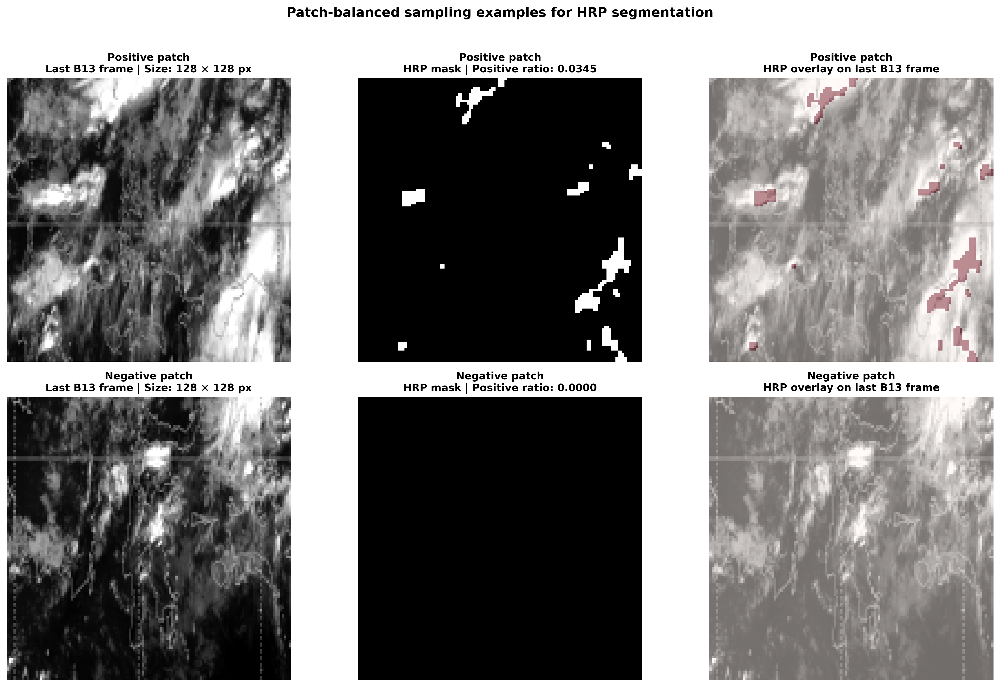

In [20]:
# ============================================================
# 12. VISUALIZE PATCH-BALANCED SAMPLING EXAMPLES
#     PAPER-READY VERSION
# ============================================================

def show_patch_examples_paper_ready(save=True, dpi=300):
    """
    Visualize positive and negative patch examples in a paper-ready format.

    Important:
    - The patch data are not resized or altered.
    - Display size is enlarged only for visualization.
    - Positive and negative patches are shown to explain patch-balanced sampling.
    """

    examples = [
        ("Positive patch", pos_x, pos_y),
        ("Negative patch", neg_x, neg_y),
    ]

    fig = plt.figure(figsize=(16, 10), dpi=dpi)

    for row_idx, (title, xp, yp) in enumerate(examples):
        last_b13 = xp[-1, ..., INPUT_PRODUCTS.index("b13")]
        mask = yp[..., 0]

        # ----------------------------------------------------
        # A. Last B13 frame patch
        # ----------------------------------------------------
        ax = plt.subplot(2, 3, row_idx * 3 + 1)
        ax.imshow(last_b13, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(
            f"{title}\nLast B13 frame | Size: {last_b13.shape[1]} × {last_b13.shape[0]} px",
            fontsize=11,
            fontweight="bold"
        )
        ax.axis("off")

        # ----------------------------------------------------
        # B. HRP patch mask
        # ----------------------------------------------------
        ax = plt.subplot(2, 3, row_idx * 3 + 2)
        ax.imshow(mask, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(
            f"{title}\nHRP mask | Positive ratio: {mask.mean():.4f}",
            fontsize=11,
            fontweight="bold"
        )
        ax.axis("off")

        # ----------------------------------------------------
        # C. Overlay patch
        # ----------------------------------------------------
        ax = plt.subplot(2, 3, row_idx * 3 + 3)
        ax.imshow(last_b13, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        ax.imshow(mask, cmap="Reds", alpha=0.45, vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(
            f"{title}\nHRP overlay on last B13 frame",
            fontsize=11,
            fontweight="bold"
        )
        ax.axis("off")

    plt.suptitle(
        "Patch-balanced sampling examples for HRP segmentation",
        fontsize=14,
        fontweight="bold",
        y=1.02
    )

    plt.tight_layout()

    if save:
        out_path = FIG_DIR / "figure_patch_balanced_sampling_examples_paper_ready.png"
        fig.savefig(out_path, dpi=dpi, bbox_inches="tight")
        print("Saved:", out_path)

    plt.show()


show_patch_examples_paper_ready(save=True, dpi=300)

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\positive_patch_b13_last_frame.png


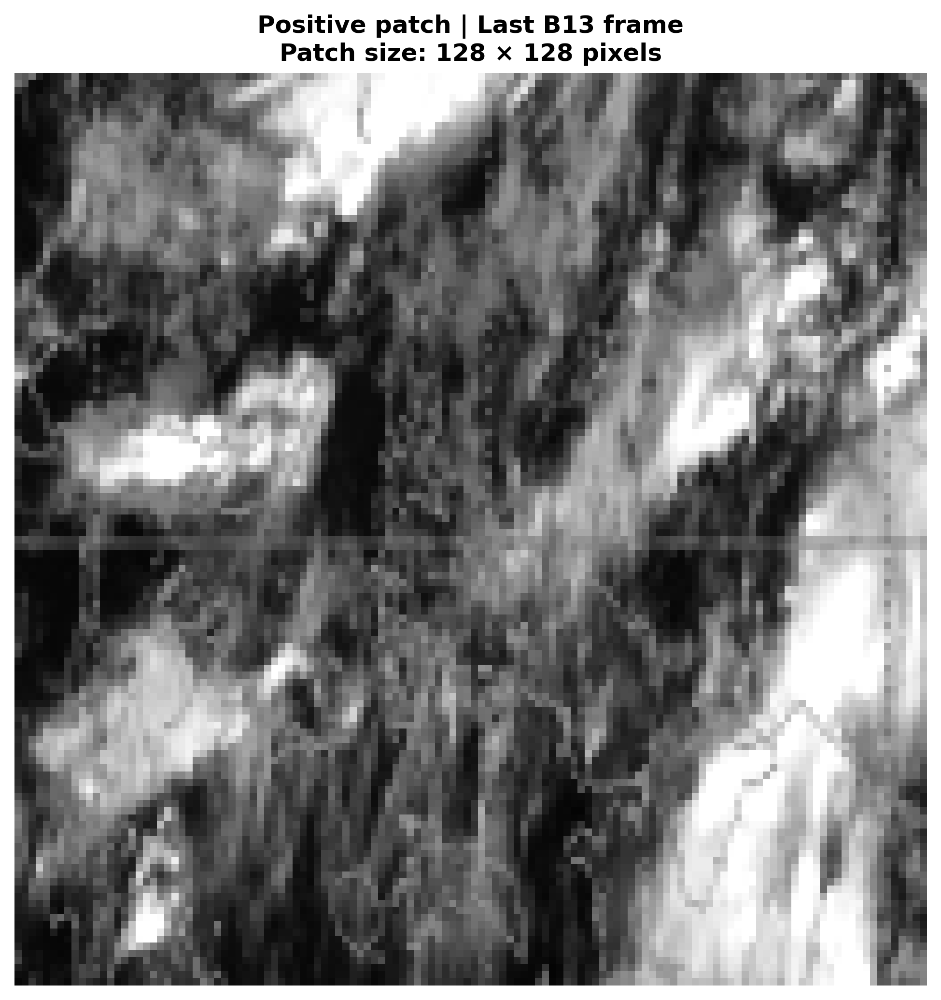

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\positive_patch_hrp_mask.png


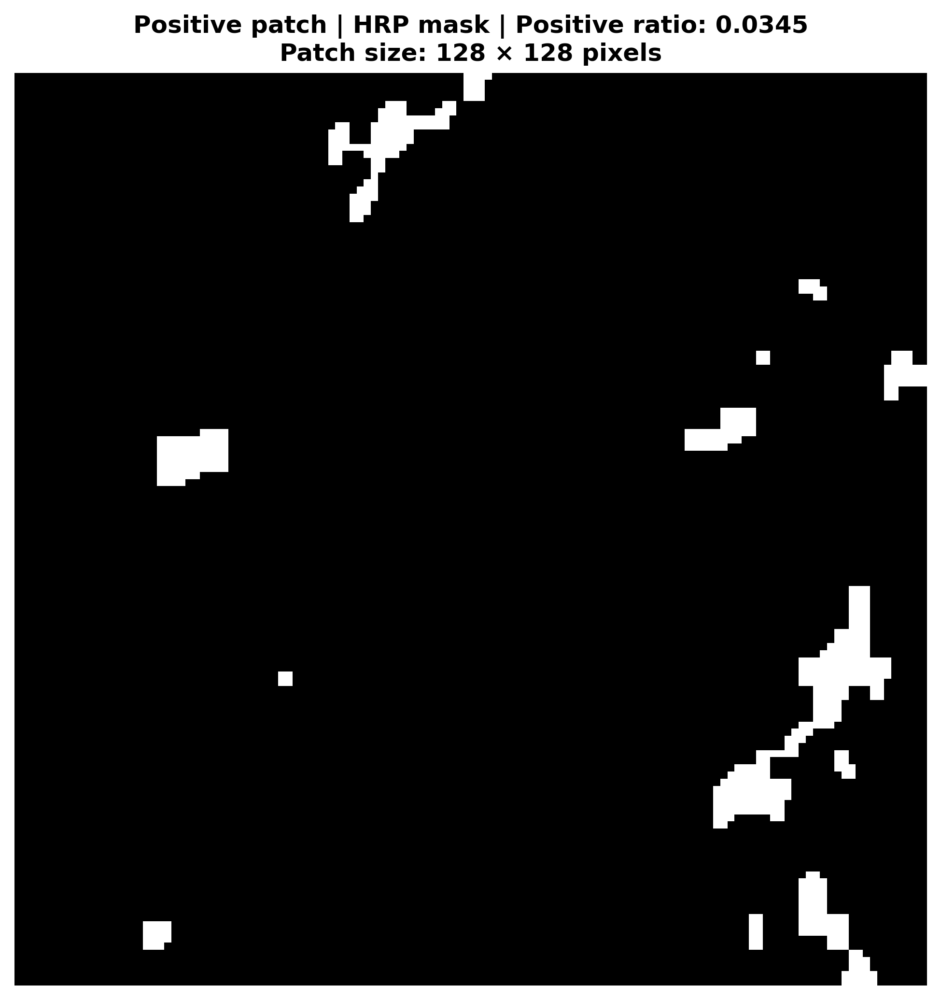

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\positive_patch_overlay.png


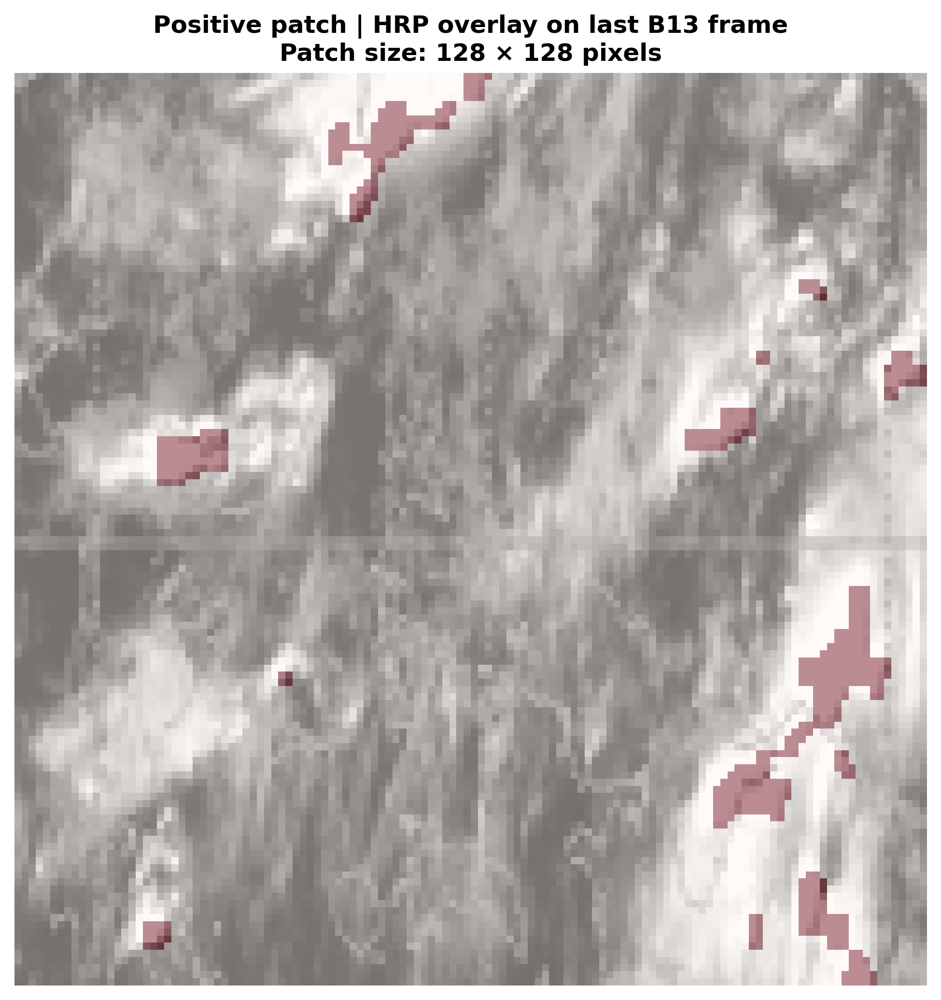

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\negative_patch_b13_last_frame.png


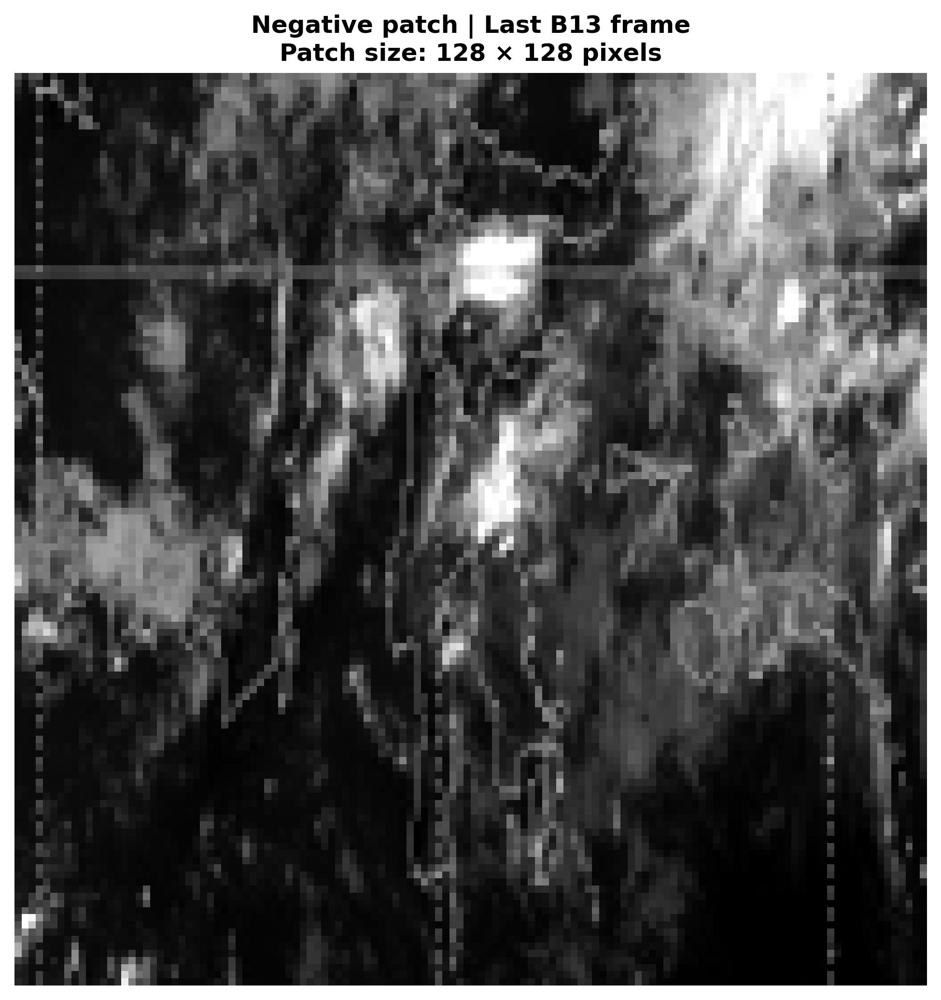

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\negative_patch_hrp_mask.png


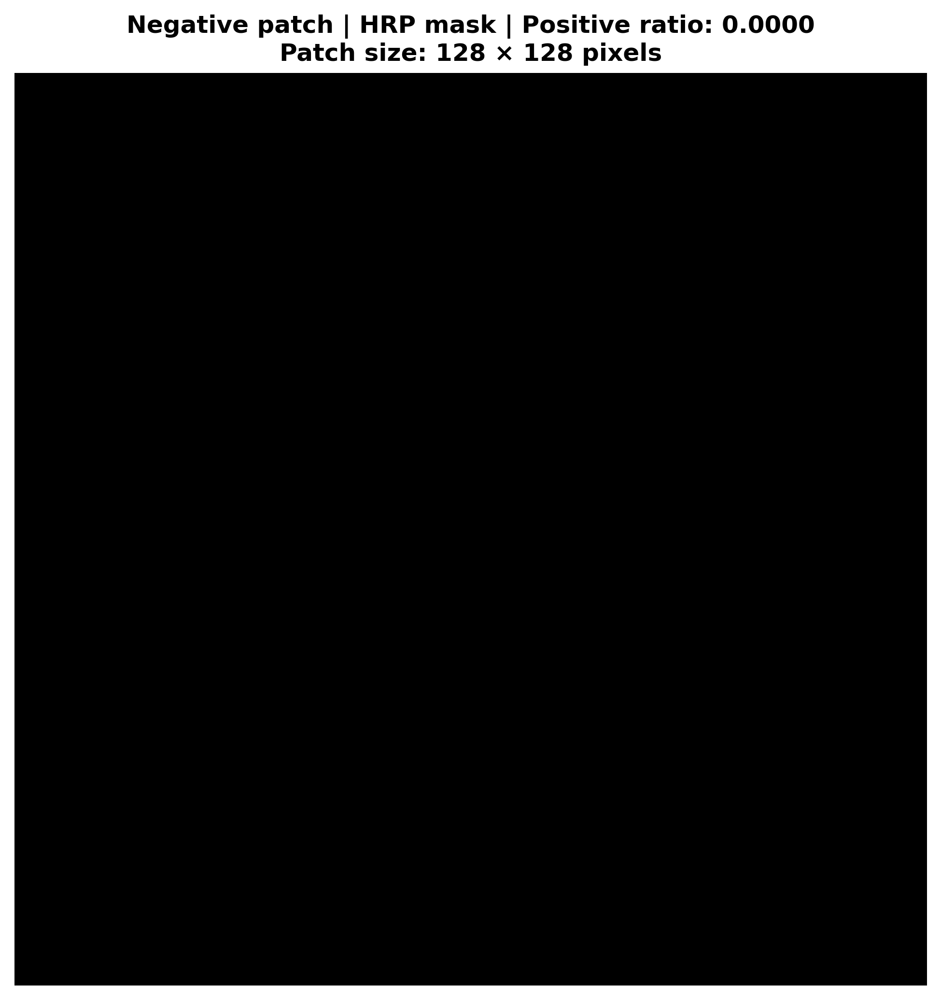

Saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\figures\negative_patch_overlay.png


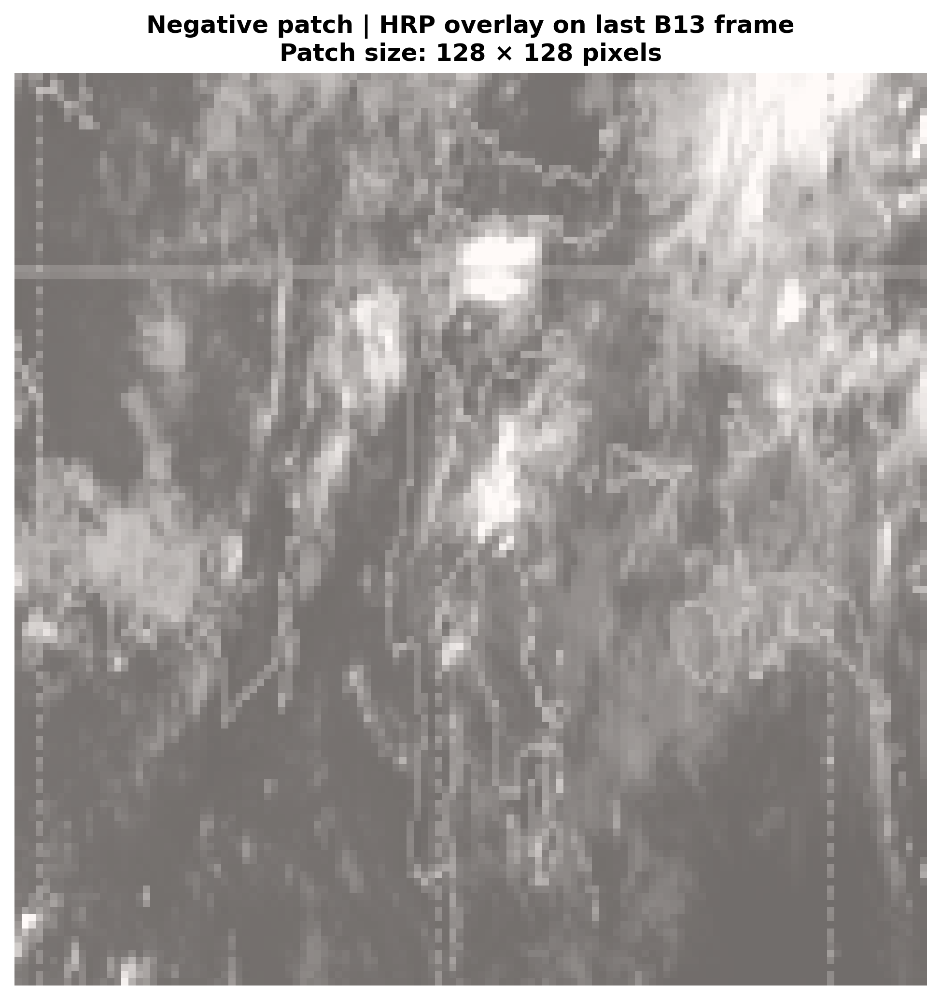

In [21]:
# ============================================================
# 12B. VISUALIZE PATCH-BALANCED SAMPLING EXAMPLES
#      SEPARATE IMAGE VERSION
# ============================================================

def show_patch_examples_separately(save=True, dpi=300):
    """
    Display and save each patch component separately:
    - positive patch B13
    - positive patch HRP mask
    - positive patch overlay
    - negative patch B13
    - negative patch HRP mask
    - negative patch overlay
    """

    examples = [
        ("positive_patch", "Positive patch", pos_x, pos_y),
        ("negative_patch", "Negative patch", neg_x, neg_y),
    ]

    for file_tag, title, xp, yp in examples:
        last_b13 = xp[-1, ..., INPUT_PRODUCTS.index("b13")]
        mask = yp[..., 0]

        items = [
            ("b13_last_frame", last_b13, "gray", f"{title} | Last B13 frame"),
            ("hrp_mask", mask, "gray", f"{title} | HRP mask | Positive ratio: {mask.mean():.4f}"),
            ("overlay", None, None, f"{title} | HRP overlay on last B13 frame"),
        ]

        for item_tag, img, cmap, item_title in items:
            plt.figure(figsize=(7, 7), dpi=dpi)

            if item_tag == "overlay":
                plt.imshow(last_b13, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
                plt.imshow(mask, cmap="Reds", alpha=0.45, vmin=0, vmax=1, interpolation="nearest")
            else:
                plt.imshow(img, cmap=cmap, vmin=0, vmax=1, interpolation="nearest")

            plt.title(
                f"{item_title}\nPatch size: {last_b13.shape[1]} × {last_b13.shape[0]} pixels",
                fontsize=12,
                fontweight="bold"
            )
            plt.axis("off")
            plt.tight_layout()

            if save:
                out_path = FIG_DIR / f"{file_tag}_{item_tag}.png"
                plt.savefig(out_path, dpi=dpi, bbox_inches="tight")
                print("Saved:", out_path)

            plt.show()


show_patch_examples_separately(save=True, dpi=300)

In [14]:

# ============================================================
# 13. EXPORT DATASET SUMMARY TABLE FOR METHODOLOGY SECTION
# ============================================================

dataset_summary = {
    "data_source": "JMA Himawari r2w Southeast Asia large-area imagery",
    "study_region": "Indonesia within the Southeast Asia Himawari scene",
    "original_domain_coverage": "Approximately 90E-165E and 30N-15S",
    "indonesia_crop": "Approximately 95E-141E and 6N-11S",
    "input_products": ", ".join(INPUT_PRODUCTS),
    "target_product": TARGET_PRODUCT.upper() + " as Himawari-derived heavy rainfall potential pseudo-label",
    "supporting_product": ", ".join(OPTIONAL_PRODUCTS) + " for contextual visualization only",
    "valid_timestamps": int(len(manifest)),
    "temporal_sequence_length": int(SEQ_LEN),
    "number_of_sequences": int(len(X)),
    "full_image_resolution": f"{IMG_SIZE[0]} x {IMG_SIZE[1]} pixels",
    "training_patch_size": f"{PATCH_SIZE} x {PATCH_SIZE} pixels",
    "train_sequences": int(len(X_train)),
    "validation_sequences": int(len(X_val)),
    "test_sequences": int(len(X_test)),
    "overall_positive_pixel_ratio": float(y.mean()),
    "train_positive_pixel_ratio": float(y_train.mean()),
    "validation_positive_pixel_ratio": float(y_val.mean()),
    "test_positive_pixel_ratio": float(y_test.mean()),
}

dataset_summary_df = pd.DataFrame(list(dataset_summary.items()), columns=["Component", "Description"])
dataset_summary_csv = TABLE_DIR / "table_dataset_configuration.csv"
dataset_summary_json = TABLE_DIR / "dataset_summary.json"

dataset_summary_df.to_csv(dataset_summary_csv, index=False)
with open(dataset_summary_json, "w", encoding="utf-8") as f:
    json.dump(dataset_summary, f, indent=2)

display(dataset_summary_df)

print("Dataset configuration table saved:", dataset_summary_csv)
print("Dataset summary JSON saved:", dataset_summary_json)


,Component,Description
0,data_source,JMA Himawari r2w Southeast Asia large-area ima...
1,study_region,Indonesia within the Southeast Asia Himawari s...
2,original_domain_coverage,Approximately 90E-165E and 30N-15S
3,indonesia_crop,Approximately 95E-141E and 6N-11S
4,input_products,"b13, b08, b07, b03"
5,target_product,HRP as Himawari-derived heavy rainfall potenti...
6,supporting_product,snd for contextual visualization only
7,valid_timestamps,142
8,temporal_sequence_length,4
9,number_of_sequences,139


Dataset configuration table saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\tables\table_dataset_configuration.csv
Dataset summary JSON saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\tables\dataset_summary.json


In [15]:

# ============================================================
# 14. EXPORT PREPROCESSING WORKFLOW SUMMARY
# ============================================================

preprocessing_steps = pd.DataFrame([
    {
        "Step": 1,
        "Stage": "Product completeness check",
        "Procedure": "Retain timestamps containing B13, B08, B07, B03, HRP, and SND.",
        "Purpose": "Ensure multispectral input and target consistency."
    },
    {
        "Step": 2,
        "Stage": "Indonesia-region cropping",
        "Procedure": "Crop the r2w Southeast Asia scene to approximately 95E-141E and 6N-11S.",
        "Purpose": "Focus the experiment on Indonesia and reduce irrelevant spatial area."
    },
    {
        "Step": 3,
        "Stage": "Spatial resizing",
        "Procedure": "Resize each cropped image to 256 x 256 pixels.",
        "Purpose": "Standardize input size for sequence construction and model evaluation."
    },
    {
        "Step": 4,
        "Stage": "Input-channel preparation",
        "Procedure": "Convert B13, B08, B07, and B03 to normalized grayscale channels and stack them.",
        "Purpose": "Build the multispectral model input tensor."
    },
    {
        "Step": 5,
        "Stage": "HRP pseudo-label extraction",
        "Procedure": "Extract magenta-colored HRP regions using RGB-HSV constraints and light morphology.",
        "Purpose": "Generate binary heavy rainfall potential segmentation masks."
    },
    {
        "Step": 6,
        "Stage": "Temporal sequence generation",
        "Procedure": "Combine four consecutive timestamps into one input sequence.",
        "Purpose": "Represent short-term cloud evolution."
    },
    {
        "Step": 7,
        "Stage": "Chronological split",
        "Procedure": "Split sequences into train, validation, and test subsets in temporal order.",
        "Purpose": "Reduce leakage among adjacent satellite scenes."
    },
    {
        "Step": 8,
        "Stage": "Patch-balanced sampling",
        "Procedure": "Illustrate positive and negative patch extraction from the training subset.",
        "Purpose": "Document how sparse HRP targets are handled during model training."
    },
])

preprocessing_steps_csv = TABLE_DIR / "table_preprocessing_workflow.csv"
preprocessing_steps.to_csv(preprocessing_steps_csv, index=False)

display(preprocessing_steps)
print("Preprocessing workflow table saved:", preprocessing_steps_csv)


,Step,Stage,Procedure,Purpose
0,1,Product completeness check,"Retain timestamps containing B13, B08, B07, B0...",Ensure multispectral input and target consiste...
1,2,Indonesia-region cropping,Crop the r2w Southeast Asia scene to approxima...,Focus the experiment on Indonesia and reduce i...
2,3,Spatial resizing,Resize each cropped image to 256 x 256 pixels.,Standardize input size for sequence constructi...
3,4,Input-channel preparation,"Convert B13, B08, B07, and B03 to normalized g...",Build the multispectral model input tensor.
4,5,HRP pseudo-label extraction,Extract magenta-colored HRP regions using RGB-...,Generate binary heavy rainfall potential segme...
5,6,Temporal sequence generation,Combine four consecutive timestamps into one i...,Represent short-term cloud evolution.
6,7,Chronological split,"Split sequences into train, validation, and te...",Reduce leakage among adjacent satellite scenes.
7,8,Patch-balanced sampling,Illustrate positive and negative patch extract...,Document how sparse HRP targets are handled du...


Preprocessing workflow table saved: outputs\ST_HRPNet_v1_Dataset_Preprocessing\dataset_preprocessing_20260602_0548UTC\tables\table_preprocessing_workflow.csv



## Output files produced by this notebook

The notebook exports the following materials for the Methodology section:

**Tables**
- `table_dataset_configuration.csv`
- `dataset_split_summary.csv`
- `table_preprocessing_workflow.csv`
- `sequence_metadata.csv`
- `dataset_manifest.csv`
- `patch_sampling_examples.csv`

**Figures**
- `figure_dataset_sample_and_hrp_mask.png`
- `figure_temporal_sequence_sample_*.png`
- `figure_patch_balanced_sampling_examples.png`

These files can be used as supporting material for the dataset subsection and as references for the methodology narrative.
